# 07i Which model is best

07h scored eight time-series models on the same 150 products and six forecast dates. This notebook reads those
scores and asks which model is best, and how sure we can be. It ranks the models on six error measures, tests every
gap product by product, counts how many products each model wins, and puts the stock cost next to the accuracy.
Nothing is refitted or retuned: every forecast here is one 07h saved. The only new numbers are the stock simulation
for the contenders 11e did not simulate, run with 11e's code on the saved forecasts.

In [1]:
import sys, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import RAW, PROCESSED, TABLES, FIGS, ORIGINS, EVAL_ORIGINS, SEED, LEAD_TIME, HOLDING_RATE, \
    STOCKOUT_MULTIPLE, FIG_STYLE
import ts_models as tm
from metrics import paired_test, holm_adjust
from break_detection import weekly_ca_prices
from pipeline import price_daily_frame, simulate_inventory, summarise_inventory, intermittency
from model_verdict import LABEL, TESTED, verdict

plt.rcParams.update(FIG_STYLE)
written = []

# the eight contenders of 07h; 'ets' is the damped Holt-Winters fitted after a Box-Cox transform
EIGHT = ["seasonal_naive", "ets", "sarima", "sarimax", "theta", "prophet", "autots", "combination"]
NAME = {"seasonal_naive": "Seasonal naive", "ets": "Holt-Winters (damped, Box-Cox)", "sarima": "SARIMA",
        "sarimax": "SARIMAX", "theta": "Theta", "prophet": "Prophet", "autots": "AutoTS", "combination": "Combination"}
METRICS = list(LABEL)

## The scores

`ts_item_scores.csv` holds each product's error per model, averaged over the six scored forecast dates. Every
summary below is the median across products, as in 07h. MAPE leaves out days with no sales, because a zero day
cannot be divided by; the share left out is printed.

In [2]:
pi = pd.read_csv(TABLES / "ts_item_scores.csv")
pi = pi[pi["model"].isin(EIGHT)]
head = pd.read_csv(TABLES / "ts_headline.csv").set_index("model")
fc = pd.read_parquet(TABLES / "ts_forecasts.parquet", filters=[("model", "in", EIGHT)])
fc = fc[fc["origin"].isin(EVAL_ORIGINS)]

assert pi.groupby("model")["item_id"].nunique().eq(150).all() and pi[METRICS].notna().all().all()
n = pi["item_id"].nunique()
print(f"{n} products, {pi['model'].nunique()} models, {len(EVAL_ORIGINS)} scored forecast dates")
print(f"MAPE leaves out {(fc.drop_duplicates(['item_id', 'date'])['actual'] == 0).mean():.1%} of product-days (no sales)")

150 products, 8 models, 6 scored forecast dates
MAPE leaves out 5.4% of product-days (no sales)


## Medians, for all products and by category

In [3]:
med = pi.groupby("model")[METRICS].median().loc[EIGHT].assign(group="ALL")
cat = pi.groupby(["category", "model"])[METRICS].median().reset_index().rename(columns={"category": "group"})
tab = pd.concat([med.reset_index(), cat], ignore_index=True)
tab["name"] = tab["model"].map(NAME)
tab["n_products"] = tab["group"].map(pi.groupby("category")["item_id"].nunique()).fillna(n).astype(int)
tab = tab[["group", "model", "name", "n_products"] + METRICS]

# check: the medians are 07h's
gap = (med[METRICS] - head.loc[EIGHT, METRICS]).abs().to_numpy().max()
print(f"largest difference from ts_headline.csv: {gap:.1e}")
assert gap < 1e-9

tab.to_csv(TABLES / "verdict_metrics.csv", index=False)
written.append(TABLES / "verdict_metrics.csv")
med[METRICS].rename(index=NAME, columns=LABEL).sort_values("RMSE").round(3)

largest difference from ts_headline.csv: 8.9e-16


,RMSE,MAE,MAPE,sMAPE,WAPE,MASE
model,,,,,,
Combination,4.392,3.499,0.586,0.469,0.437,0.747
SARIMA,4.445,3.522,0.603,0.474,0.435,0.755
"Holt-Winters (damped, Box-Cox)",4.513,3.543,0.560,0.474,0.434,0.744
Theta,4.541,3.510,0.602,0.480,0.442,0.756
SARIMAX,4.583,3.650,0.609,0.466,0.441,0.760
AutoTS,4.848,3.885,0.626,0.502,0.466,0.831
Prophet,4.913,3.859,0.622,0.482,0.445,0.760
Seasonal naive,6.039,4.720,0.753,0.616,0.581,0.973


In [4]:
cat.pivot(index="model", columns="group", values="rmse").loc[EIGHT].rename(index=NAME).round(3)

group,FOODS,HOBBIES,HOUSEHOLD
model,,,
Seasonal naive,10.318,4.221,4.711
"Holt-Winters (damped, Box-Cox)",8.150,3.131,3.660
SARIMA,7.998,3.179,3.646
SARIMAX,8.155,3.213,3.696
Theta,8.159,3.208,3.708
Prophet,8.350,3.143,3.739
AutoTS,8.919,3.388,4.106
Combination,8.005,3.167,3.663


## Ranks

Each model's rank on each measure (1 = lowest median error), the average rank over the six, and how often it is
first, in the top two and in the top three. The average rank shows which model is good on every measure, not only
on the one it happens to lead.

In [5]:
rk = med[METRICS].rank(method="min").astype(int)
ranks = rk.add_prefix("rank_")
ranks["avg_rank"] = rk.mean(axis=1)
ranks["n_first"] = (rk == 1).sum(axis=1)
ranks["n_top2"] = (rk <= 2).sum(axis=1)
ranks["n_top3"] = (rk <= 3).sum(axis=1)
ranks.insert(0, "name", ranks.index.map(NAME))
ranks = ranks.sort_values("avg_rank")
ranks.to_csv(TABLES / "verdict_ranks.csv", index_label="model")
written.append(TABLES / "verdict_ranks.csv")
ranks.drop(columns="name").rename(index=NAME)

,rank_rmse,rank_mae,rank_mape,rank_smape,rank_wape,rank_mase,avg_rank,n_first,n_top2,n_top3
model,,,,,,,,,,
Combination,1,1,2,2,3,2,1.833333,2,5,6
"Holt-Winters (damped, Box-Cox)",3,4,1,3,1,1,2.166667,3,3,5
SARIMA,2,3,4,4,2,3,3.000000,0,2,4
Theta,4,2,3,5,5,4,3.833333,0,1,2
SARIMAX,5,5,5,1,4,6,4.333333,1,1,1
Prophet,7,6,6,6,6,5,6.000000,0,0,0
AutoTS,6,7,7,7,7,7,6.833333,0,0,0
Seasonal naive,8,8,8,8,8,8,8.000000,0,0,0


## Are the gaps real?

For RMSE, MAE and MASE, every model is compared with every other one, product by product: a paired Wilcoxon test on
the 150 per-product differences, Holm-corrected within each reference model and measure (seven tests), and a
bootstrap 95% interval for the median difference. A gap counts as real only when the interval leaves out zero and
the Holm p-value is below 0.05; otherwise it is a tie. The gap is also given as a percentage of the reference
model's median error. The tables against Combination and against SARIMA are the ones asked for; the rest let the
dashboard compare with whichever model leads.

In [6]:
rows = []
for k in TESTED:
    wd = pi.pivot(index="item_id", columns="model", values=k)
    for ref in EIGHT:
        part = [{"metric": k, "reference": ref, "model": m, **paired_test(wd[m] - wd[ref], seed=SEED)}
                for m in EIGHT if m != ref]
        for r, p in zip(part, holm_adjust([r["p_value"] for r in part])):
            r["p_holm"] = p
            r["ref_median"] = med.loc[ref, k]
            r["gap_pct"] = r["median_diff"] / med.loc[ref, k]
            real = p < 0.05 and (r["ci_low"] > 0 or r["ci_high"] < 0)
            r["result"] = "tie" if not real else ("worse" if r["median_diff"] > 0 else "better")
        rows += part
tests = pd.DataFrame(rows)[["metric", "reference", "model", "n", "median_diff", "ci_low", "ci_high", "gap_pct",
                            "share_improved", "p_value", "p_holm", "result"]]
assert tests[["median_diff", "ci_low", "ci_high", "p_value", "p_holm"]].notna().all().all()

# check: the raw tests against SARIMA are 07h's (07h's Holm family is larger, so only the raw p-values compare)
old = pd.read_csv(TABLES / "ts_tests.csv").query("metric in ['rmse', 'mae'] and model in @EIGHT and model != 'sarima'")
new = tests[tests["reference"] == "sarima"].merge(old, on=["metric", "model"], suffixes=("", "_07h"))
gap = max((new["p_value"] - new["p_value_07h"]).abs().max(), (new["ci_low"] - new["ci_low_07h"]).abs().max())
print(f"{len(new)} tests against SARIMA compared with 07h; largest difference {gap:.1e}")
assert gap < 1e-12

tests.to_csv(TABLES / "verdict_tests.csv", index=False)
written.append(TABLES / "verdict_tests.csv")
show = tests[tests["reference"].isin(["combination", "sarima"])].assign(model=lambda d: d["model"].map(NAME))
show.pivot_table(index="model", columns=["reference", "metric"], values="result", aggfunc="first")

14 tests against SARIMA compared with 07h; largest difference 6.7e-16


reference                      combination                sarima          \
metric                                 mae   mase   rmse     mae    mase   
model                                                                      
AutoTS                               worse  worse  worse   worse   worse   
Combination                            NaN    NaN    NaN  better  better   
Holt-Winters (damped, Box-Cox)         tie    tie  worse     tie     tie   
Prophet                              worse  worse    tie   worse   worse   
SARIMA                               worse  worse  worse     NaN     NaN   
SARIMAX                              worse  worse  worse     tie     tie   
Seasonal naive                       worse  worse  worse   worse   worse   
Theta                                worse  worse  worse     tie     tie   

reference                               
metric                            rmse  
model                                   
AutoTS                           worse  
Combination                     better  
Holt-Winters (damped, Box-Cox)     tie  
Prophet                            tie  
SARIMA                             NaN  
SARIMAX                          worse  
Seasonal naive                   worse  
Theta                              tie

In [7]:
show[show["metric"] == "rmse"][["reference", "model", "median_diff", "ci_low", "ci_high", "gap_pct", "p_holm",
                                "result"]].round(4).to_string(index=False)

'  reference                          model  median_diff  ci_low  ci_high  gap_pct  p_holm result\n     sarima                 Seasonal naive       1.3976  1.1428   1.6671   0.3144  0.0000  worse\n     sarima Holt-Winters (damped, Box-Cox)       0.0084 -0.0124   0.0298   0.0019  0.2624    tie\n     sarima                        SARIMAX       0.0181  0.0097   0.0379   0.0041  0.0005  worse\n     sarima                          Theta      -0.0024 -0.0154   0.0162  -0.0005  0.3079    tie\n     sarima                        Prophet       0.0211 -0.0094   0.0540   0.0047  0.1541    tie\n     sarima                         AutoTS       0.4051  0.3167   0.5356   0.0911  0.0000  worse\n     sarima                    Combination      -0.0238 -0.0412  -0.0057  -0.0054  0.0304 better\ncombination                 Seasonal naive       1.5056  1.2608   1.6987   0.3428  0.0000  worse\ncombination Holt-Winters (damped, Box-Cox)       0.0439  0.0297   0.0602   0.0100  0.0000  worse\ncombination        

## Product by product: who wins where

For each product and measure, the model with the lowest error wins that product. A model can have the best median
and still win few products, when it is close to the best everywhere and first nowhere.

In [8]:
rows = []
for k in METRICS:
    win = pi.pivot(index="item_id", columns="model", values=k)[EIGHT].idxmin(axis=1).value_counts()
    rows += [{"metric": k, "model": m, "name": NAME[m], "wins": int(win.get(m, 0)), "share": win.get(m, 0) / n}
             for m in EIGHT]
wins = pd.DataFrame(rows)
wins.to_csv(TABLES / "verdict_wins.csv", index=False)
written.append(TABLES / "verdict_wins.csv")
wins.pivot(index="name", columns="metric", values="wins")[METRICS].rename(columns=LABEL)

metric,RMSE,MAE,MAPE,sMAPE,WAPE,MASE
name,,,,,,
AutoTS,1,2,3,3,1,2
Combination,19,13,4,22,12,13
"Holt-Winters (damped, Box-Cox)",30,64,89,36,63,64
Prophet,49,32,23,33,35,32
SARIMA,22,14,15,23,14,14
SARIMAX,18,17,10,23,14,17
Seasonal naive,0,0,2,0,3,0
Theta,11,8,4,10,8,8


## Accuracy and money side by side

11e put the 07a models through the stock simulation on these 150 products; most of the eight contenders were not
in it. Here every contender goes through the same simulation with 11e's code and settings (95% target, 7-day lead
time, the assumed base costs), on the forecasts 07h saved: once with the textbook safety stock and once with safety
stock sized from past errors (the 11c rule). Where 11e simulated the same forecasts, the results must match it.
This part reads files that 09 and 11e write, so `scripts/run_all.py` runs this notebook after 11e.

In [9]:
inp = tm.load_inputs()
sample = inp["sample"]
long_df = inp["long_df"][inp["long_df"]["item_id"].isin(sample["item_id"])]
calendar = pd.read_csv(RAW / "calendar.csv", parse_dates=["date"])
prices = pd.read_csv(RAW / "sell_prices.csv", dtype={"store_id": "category"})
price_wk = weekly_ca_prices(prices, calendar, sample["item_id"].tolist())
del prices
days = pd.date_range(ORIGINS[1] + pd.Timedelta(days=1), periods=28 * 6)
price_daily = price_daily_frame(price_wk, days)
inter = intermittency(long_df, ORIGINS[0])
# the MASE scales 09 saved and 11e uses: recomputing them gives the same numbers to 1e-15, but the simulation rounds
# order sizes, so even that can move one product's cost by a few dollars; reading the same file keeps 11e's results
scales = pd.read_csv(PROCESSED / "backtest_errors.csv", parse_dates=["origin"])[["item_id", "origin", "mase_scale"]]
scales = scales.drop_duplicates(["item_id", "origin"])

sf = pd.read_parquet(TABLES / "ts_forecasts.parquet", filters=[("model", "in", EIGHT)])
sf = sf[sf["origin"].isin(ORIGINS)][["item_id", "origin", "date", "model", "forecast", "actual", "category"]]
sf = sf.assign(variant="static")
print(sf.groupby("model")["item_id"].nunique().to_dict())

{'autots': 150, 'combination': 150, 'ets': 150, 'prophet': 150, 'sarima': 150, 'sarimax': 150, 'seasonal_naive': 150, 'theta': 150}


In [10]:
SL = 0.95
POL = [(m, "static") for m in EIGHT]
normal = simulate_inventory(sf, ORIGINS, price_daily, POL, [SL], LEAD_TIME, inter, HOLDING_RATE, STOCKOUT_MULTIPLE)

# safety stock from past errors: 11e's rule, pooled scaled 7-day error sums within category and model
f = sf.merge(scales, on=["item_id", "origin"])
f["e"] = f["actual"] - f["forecast"]
sums = []
for (item, origin, model, c), g in f.groupby(["item_id", "origin", "model", "category"]):
    s = np.convolve(g.sort_values("date")["e"].to_numpy(), np.ones(LEAD_TIME), mode="valid") / g["mase_scale"].iloc[0]
    sums.append(pd.DataFrame({"origin": origin, "model": model, "category": c, "r7": s}))
sums = pd.concat(sums, ignore_index=True)
scale_of = scales.set_index(["item_id", "origin"])["mase_scale"]
cat_of = sample.set_index("item_id")["category"]
cache = {}

def conformal_ss(item, model, variant, origin, lead_time, sl, past_errors):
    key = (cat_of[item], model, origin, sl)
    if key not in cache:
        pool = sums[(sums["category"] == key[0]) & (sums["model"] == model) & (sums["origin"] < origin)]["r7"].to_numpy()
        k = len(pool)
        cache[key] = np.quantile(pool, min(1.0, np.ceil((k + 1) * sl) / k), method="higher")
    return max(0.0, scale_of[(item, origin)] * cache[key])

conf = simulate_inventory(sf, ORIGINS, price_daily, POL, [SL], LEAD_TIME, inter, HOLDING_RATE, STOCKOUT_MULTIPLE,
                          ss_fn=conformal_ss)
items = pd.concat([normal.assign(method="normal formula"), conf.assign(method="conformal")], ignore_index=True)
print(len(items), "product simulations")

2400 product simulations


In [11]:
# check: SARIMA and seasonal naive are the forecasts 11e simulated, so their rows must equal 11e's
ref = pd.read_csv(TABLES / "stock_items.csv")
chk = items[items["model"].isin(["sarima", "seasonal_naive"])].merge(
    ref, on=["item_id", "model", "method"], suffixes=("", "_11e"))
gap = (chk["total_cost"] - chk["total_cost_11e"]).abs().max()
print(f"{len(chk)} product rows compared with 11e; largest cost difference ${gap:.4f}")
assert len(chk) == 600 and gap < 0.01

600 product rows compared with 11e; largest cost difference $0.0000


In [12]:
stock = summarise_inventory(items, by=("method", "model", "service_level"))
stock["name"] = stock["model"].map(NAME)
stock = stock[["method", "model", "name", "service_level", "n_items", "total_cost", "holding_cost", "stockout_cost",
               "fill_rate", "cycle_service_level", "avg_inventory_value"]]
stock.to_csv(TABLES / "verdict_stock.csv", index=False)
written.append(TABLES / "verdict_stock.csv")
side = med[["rmse", "mase"]].join(stock[stock["method"] == "conformal"].set_index("model")[
    ["total_cost", "fill_rate", "avg_inventory_value"]])
side.rename(index=NAME).sort_values("rmse").round(3)

,rmse,mase,total_cost,fill_rate,avg_inventory_value
model,,,,,
Combination,4.392,0.747,8260.820,0.990,37962.048
SARIMA,4.445,0.755,7856.547,0.992,36983.063
"Holt-Winters (damped, Box-Cox)",4.513,0.744,9347.295,0.987,38306.018
Theta,4.541,0.756,9031.611,0.988,39298.302
SARIMAX,4.583,0.760,7586.379,0.992,38459.617
AutoTS,4.848,0.831,10519.147,0.985,41685.722
Prophet,4.913,0.760,9191.083,0.989,38175.873
Seasonal naive,6.039,0.973,8973.544,0.989,40272.006


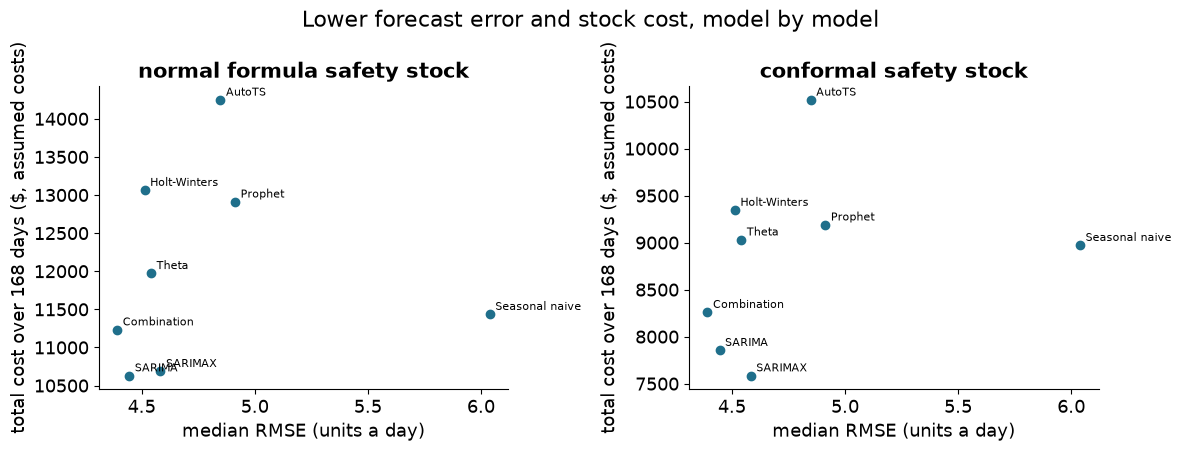

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, method in zip(axes, ["normal formula", "conformal"]):
    s = side if method == "conformal" else med[["rmse"]].join(
        stock[stock["method"] == method].set_index("model")[["total_cost"]])
    ax.scatter(s["rmse"], s["total_cost"], color="#1F6F8B")
    for m, r in s.iterrows():
        ax.annotate(NAME[m].split(" (")[0], (r["rmse"], r["total_cost"]), fontsize=8, xytext=(4, 3),
                    textcoords="offset points")
    ax.set_xlabel("median RMSE (units a day)")
    ax.set_ylabel("total cost over 168 days ($, assumed costs)")
    ax.set_title(f"{method} safety stock")
fig.suptitle("Lower forecast error and stock cost, model by model")
fig.tight_layout()
fig.savefig(FIGS / "verdict_accuracy_vs_cost.png")
written.append(FIGS / "verdict_accuracy_vs_cost.png")
plt.show()

## The verdict

The sentences below are written by `src/model_verdict.py` from the tables above, so they change if the numbers do.
The dashboard prints the same text. RMSE decides, because it was fixed before the run as the measure for picking
the stock model; ties on RMSE are broken on average rank and then on stock cost.

In [14]:
cost = stock[stock["method"] == "conformal"].set_index("model")
rec, text = verdict(med[METRICS], ranks, tests, wins, cost, NAME, EVAL_ORIGINS, n)
for s in text:
    print(s, end="\n\n")

Lowest typical error by measure: Combination on RMSE (4.392) and MAE (3.499); Holt-Winters (damped, Box-Cox) on MAPE (0.560), WAPE (0.434) and MASE (0.744); SARIMAX on sMAPE (0.466).

On RMSE, Combination is tied with Prophet at +0.7% (median difference per product; its interval includes zero), so that part of its lead is not real; it is really ahead of the other 6, by 0.5% to 34.3%. Prophet's typical RMSE is 11.9% higher, but it is close on most products and far off on a few, so the paired test cannot separate the two.

On MAE, Combination is tied with Holt-Winters (damped, Box-Cox) at -0.2% (median difference per product; its interval includes zero), so that part of its lead is not real; it is really ahead of the other 6, by 1.1% to 29.9%.

On MASE, Holt-Winters (damped, Box-Cox) is tied with SARIMA at +1.4% and Combination at +0.1% (median difference per product; its interval includes zero), so that part of its lead is not real; it is really ahead of the other 5, by 1.3% to 29.8%.



## What comes next

`08a_break_detection` turns to the other question of the project: do the products' sales levels shift, and does
it help to react when they do?

In [15]:
# files this notebook wrote
from pathlib import Path
ROOT = Path("..").resolve()
for p in written:
    print(Path(p).resolve().relative_to(ROOT), f"{Path(p).stat().st_size / 1e3:,.0f} KB")

outputs\tables\verdict_metrics.csv 5 KB
outputs\tables\verdict_ranks.csv 1 KB
outputs\tables\verdict_tests.csv 29 KB
outputs\tables\verdict_wins.csv 2 KB
outputs\tables\verdict_stock.csv 3 KB
outputs\figures\verdict_accuracy_vs_cost.png 112 KB
